# **Main Code**

 **Upload dataset which will be used for the analysis**

In [32]:
pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 1.5 MB/s eta 0:00:000:00:010:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 1.9 MB/s eta 0:00:00 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 1.6 MB/s eta 0:00:001.6 MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


**Importing necessary libraries**

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


**Read dataset**

In [41]:
file_path = "/Users/utente/Desktop/Thesis/Thesis/src/Thesis_Dataset.xlsx"
dataset = pd.read_excel(file_path)

**Filter dataset to include data from July 1969 onward to have balanced dataset**

In [43]:
# Filter the dataset for all rows where the Date is greater than or equal to July 1969
dataset = dataset[dataset['Date'] >= '1969-07']
print(dataset.shape)

(663, 50)


Missing data are indicated by -99.99 or -999.

Check presence in our data.

In [44]:
# Identify missing data values (-99.99 and -999) in the dataset
missing_data_counts = (dataset == -99.99).sum() + (dataset == -999).sum()

# Display columns with missing data counts
missing_data_present = missing_data_counts[missing_data_counts > 0]

print("Columns with missing data values (-99.99 or -999):")
print(missing_data_present)

# If you want to check the total number of such missing values in the dataset:
total_missing_data = missing_data_counts.sum()
print(f"\nTotal missing data points in the dataset: {total_missing_data}")

Columns with missing data values (-99.99 or -999):
Series([], dtype: int64)

Total missing data points in the dataset: 0


#### **Demeaning of returns**

Consistently with discussions around unobserved heterogeneity, we proceed with demeaning the returns.

This operation, effectively, makes it so that our unconditional returns are equal to 0.

In [ ]:
# Step 1: Separate the 'Date' column
dates = dataset['Date']
returns_data = dataset.loc[:, dataset.columns != 'Date']

# Step 2: Compute the mean of each portfolio
portfolio_means = returns_data.mean(axis=0)

# Step 3: Demean the returns
demeaned_returns = returns_data.subtract(portfolio_means, axis=1)

# Step 4: Verify the unconditional mean is zero
demeaned_means = demeaned_returns.mean(axis=0)
# Check that the absolute values are close to zero
print((demeaned_means.abs() < 1e-12).all())  # Should return True

# Step 5: Save back the returns dataset as "dataset"
dataset = returns_data

# Step 6: Include the 'Date' column back (optional)
#dataset = pd.concat([dates, demeaned_returns], axis=1)

True


#### **Implement estimators to obtain the optimal number of latent factors**

##### **Eigenvalue Ratio estimator**

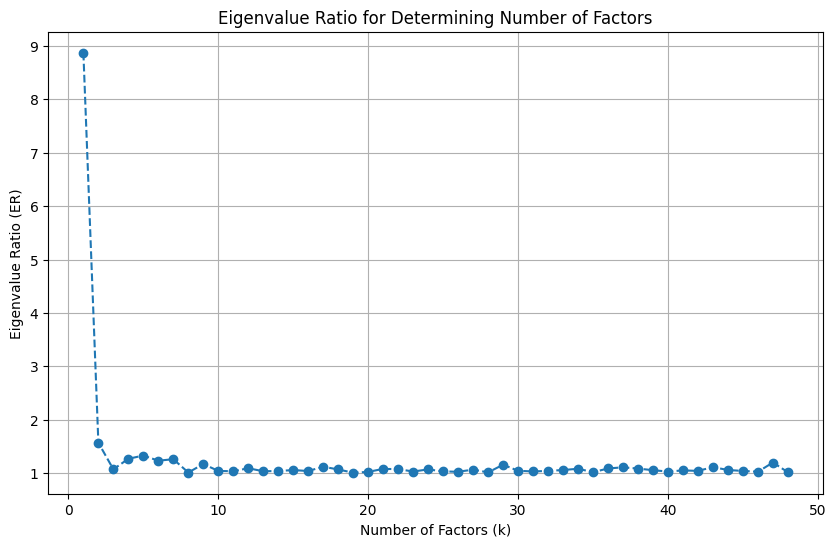

Optimal number of factors: 1


In [47]:
# Step 1: Compute the covariance matrix of the dataset
cov_matrix = dataset.cov()

# Step 2: Compute the eigenvalues of the covariance matrix
eigenvalues, _ = np.linalg.eigh(cov_matrix)

# Step 3: Sort eigenvalues in descending order
eigenvalues = np.sort(eigenvalues)[::-1]

# Step 4: Calculate the Eigenvalue Ratio (ER) for each k
er_ratios = [eigenvalues[i] / eigenvalues[i + 1] for i in range(len(eigenvalues) - 1)]

# Step 5: Find the optimal number of factors by finding the maximum ratio
optimal_num_factors = np.argmax(er_ratios) + 1

# Step 6: Plot the eigenvalue ratios for visualization
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(er_ratios) + 1), er_ratios, marker='o', linestyle='--')
plt.xlabel('Number of Factors (k)')
plt.ylabel('Eigenvalue Ratio (ER)')
plt.title('Eigenvalue Ratio for Determining Number of Factors')
plt.grid(True)
plt.show()

print(f"Optimal number of factors: {optimal_num_factors}")

##### **Growth Ratio estimator**

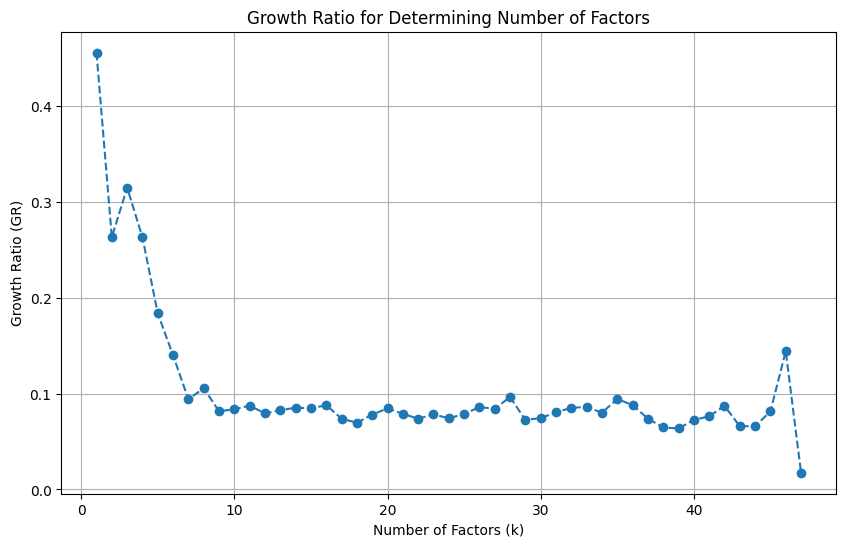

Optimal number of factors (Growth Ratio): 1


In [48]:
# Step 1: Calculate the Growth Ratio (GR) for each k
V = [np.sum(eigenvalues[i+1:]**2) / (len(eigenvalues) - (i + 1)) for i in range(len(eigenvalues) - 1)]
gr_ratios = [np.log(V[k]) - np.log(V[k + 1]) for k in range(len(V) - 1)]

# Step 2: Find the optimal number of factors by finding the maximum growth ratio
optimal_num_factors_gr = np.argmax(gr_ratios) + 1

# Step 3: Plot the growth ratios for visualization
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(gr_ratios) + 1), gr_ratios, marker='o', linestyle='--')
plt.xlabel('Number of Factors (k)')
plt.ylabel('Growth Ratio (GR)')
plt.title('Growth Ratio for Determining Number of Factors')
plt.grid(True)
plt.show()

print(f"Optimal number of factors (Growth Ratio): {optimal_num_factors_gr}")